# Đặng Quang Tiến (Người 4) — Đánh giá và phân tích lỗi

**Đóng góp:** đánh giá tích hợp, confusion matrix, per-class metrics, so sánh lỗi, ví dụ ảnh và đối chiếu EDA. Có trợ lý AI hỗ trợ, không coi thực thi tự động là xác minh cá nhân. Giữ nguyên EDA/đặc trưng/mô hình và mọi full-run/test claims của các thành viên.

**Hai tập bằng chứng tách biệt:** official test của sáu pipeline lịch sử; OOF trên train của phần nâng cấp. Không fit, predict hoặc nạp joblib khi Run All; không có điểm official test của model nâng cấp.

## 1. Dữ liệu, provenance và phạm vi đánh giá

Train39.209/Test12.630,43 lớp. Đối chiếu CSVRow/Path/ClassId trực tiếp với CSV local; xác minh selection/claim hashes và tính lại các metrics từ predictions lịch sử. Test đã được EDA thăm dò, không gọi là holdout hoàn toàn mù. Nguồn và sản phẩm đều có SHA256; không sửa ảnh/split/nhãn.

In [1]:
from pathlib import Path
import json, hashlib, sys
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
ROOT=Path.cwd().resolve()
if not (ROOT/'src').is_dir(): ROOT=ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from scripts.model_artifacts import resolve_evidence
RUN=ROOT/'report/evaluation/tien-evaluation-20261115'
PREFIX='evaluation_tien-evaluation-20261115'
TABLES=ROOT/'report/tables'
FIGURES=ROOT/'report/figures'
provenance=json.loads((RUN/'provenance.json').read_text(encoding='utf-8'))
assert provenance['fit'] is False and provenance['predict'] is False
assert provenance['joblib_deserialized'] is False
assert provenance['new_official_test_inference'] is False
print('Contributor:',provenance['contributor'],'member',provenance['member_number'])
for relative, expected in provenance['sources_sha256'].items():
    resolve_evidence(relative,expected,project_root=ROOT)
for relative, expected in provenance['outputs_sha256'].items():
    resolve_evidence(relative,expected,project_root=ROOT)
print('All recorded input/output SHA256 checks passed, including relocated KNN/DT evidence.')
print('Historical hashes are unchanged; directory relocation does not create new experiment results.')

Contributor: Đặng Quang Tiến member 4


All recorded input/output SHA256 checks passed, including relocated KNN/DT evidence.
Historical hashes are unchanged; directory relocation does not create new experiment results.


## 2. Metrics của sáu pipeline lịch sử

Accuracy phản ánh tỷ lệ ảnh đúng; Precision/Recall/F1 macro cho mỗi lớp trọng số bằng nhau. Tập chính thức có đủ43 lớp nên balanced accuracy bằng macro recall. Winner biểu diễn được chọn bằng CV trước test, không chọn lại mô hình bằng bảng này. Không diễn giải cột CV và test là cùng một phân phối hay hiệu quả có ý nghĩa thống kê.

,algorithm,method,accuracy,precision_macro,recall_macro,f1_macro,balanced_accuracy,representation_is_cv_winner
0,knn,pixel,0.557245,0.513669,0.490561,0.493948,0.490561,False
1,knn,hog,0.818369,0.813760,0.777906,0.789750,0.777906,True
2,knn,hog_pca,0.796675,0.792526,0.747460,0.763063,0.747460,False
3,dt,pixel,0.635313,0.578621,0.558620,0.563179,0.558620,False
4,dt,hog,0.656770,0.614162,0.585053,0.594987,0.585053,True
5,dt,hog_pca,0.591607,0.560685,0.522457,0.536760,0.522457,False


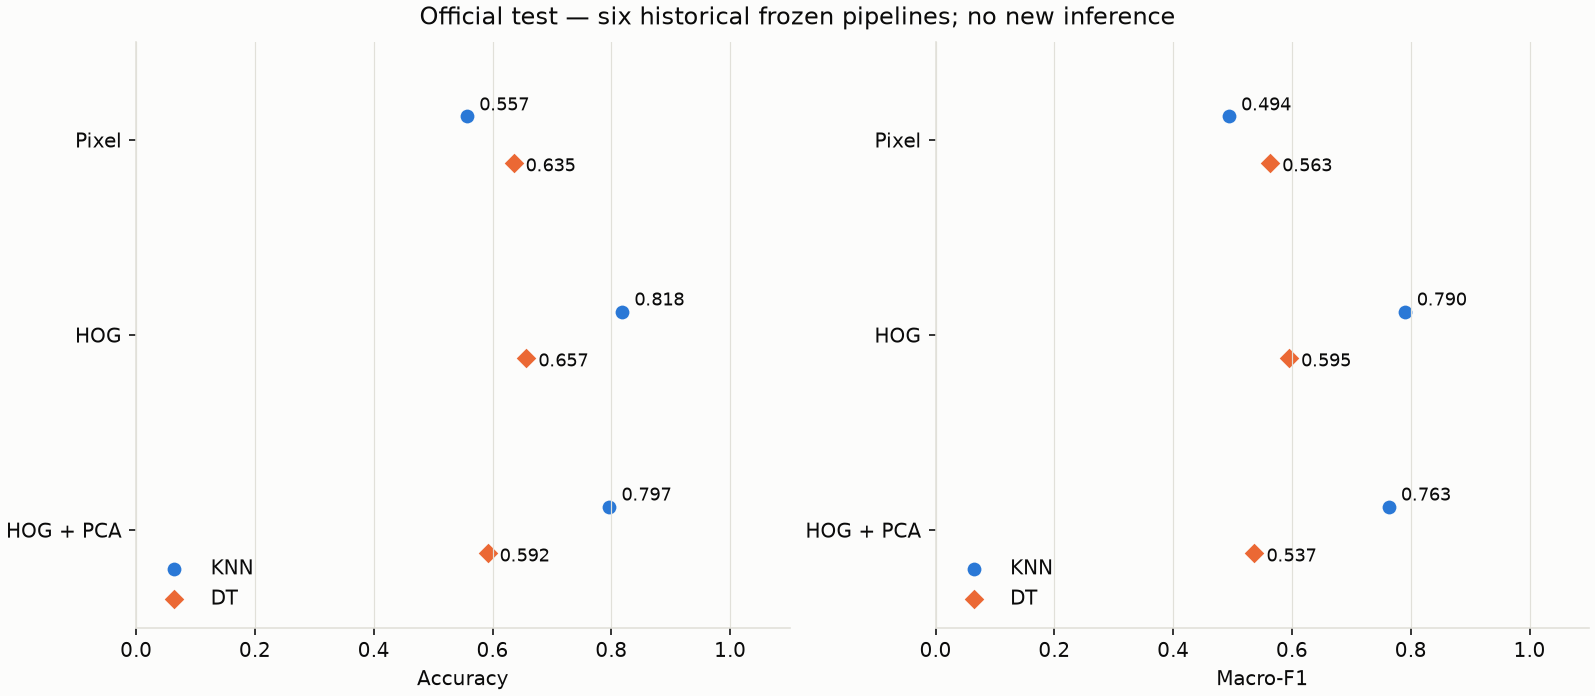

In [2]:
summary=pd.read_csv(TABLES/f'{PREFIX}_official_summary.csv')
display(summary[['algorithm','method','accuracy','precision_macro','recall_macro','f1_macro','balanced_accuracy',
 'representation_is_cv_winner']])
display(Image(filename=str(FIGURES/f'{PREFIX}_official_comparison.png')))

## 3. Confusion matrices đầy đủ và chuẩn hóa theo nhãn thật

Hàng=true, cột=predicted; chuẩn hóa mỗi hàng để không bị lớp đông chi phối. Mỗi model có cả count và row-normalized CSV43×43 dạng long. ClassId↔tên được lưu riêng. Không suy nguyên nhân ảnh mờ/tối từ ô nhầm lẫn.

,class_id,class_name
0,0,Speed limit 20
1,1,Speed limit 30
2,2,Speed limit 50
3,3,Speed limit 60
4,4,Speed limit 70
5,5,Speed limit 80
6,6,End of speed limit 80
7,7,Speed limit 100
8,8,Speed limit 120
9,9,No passing


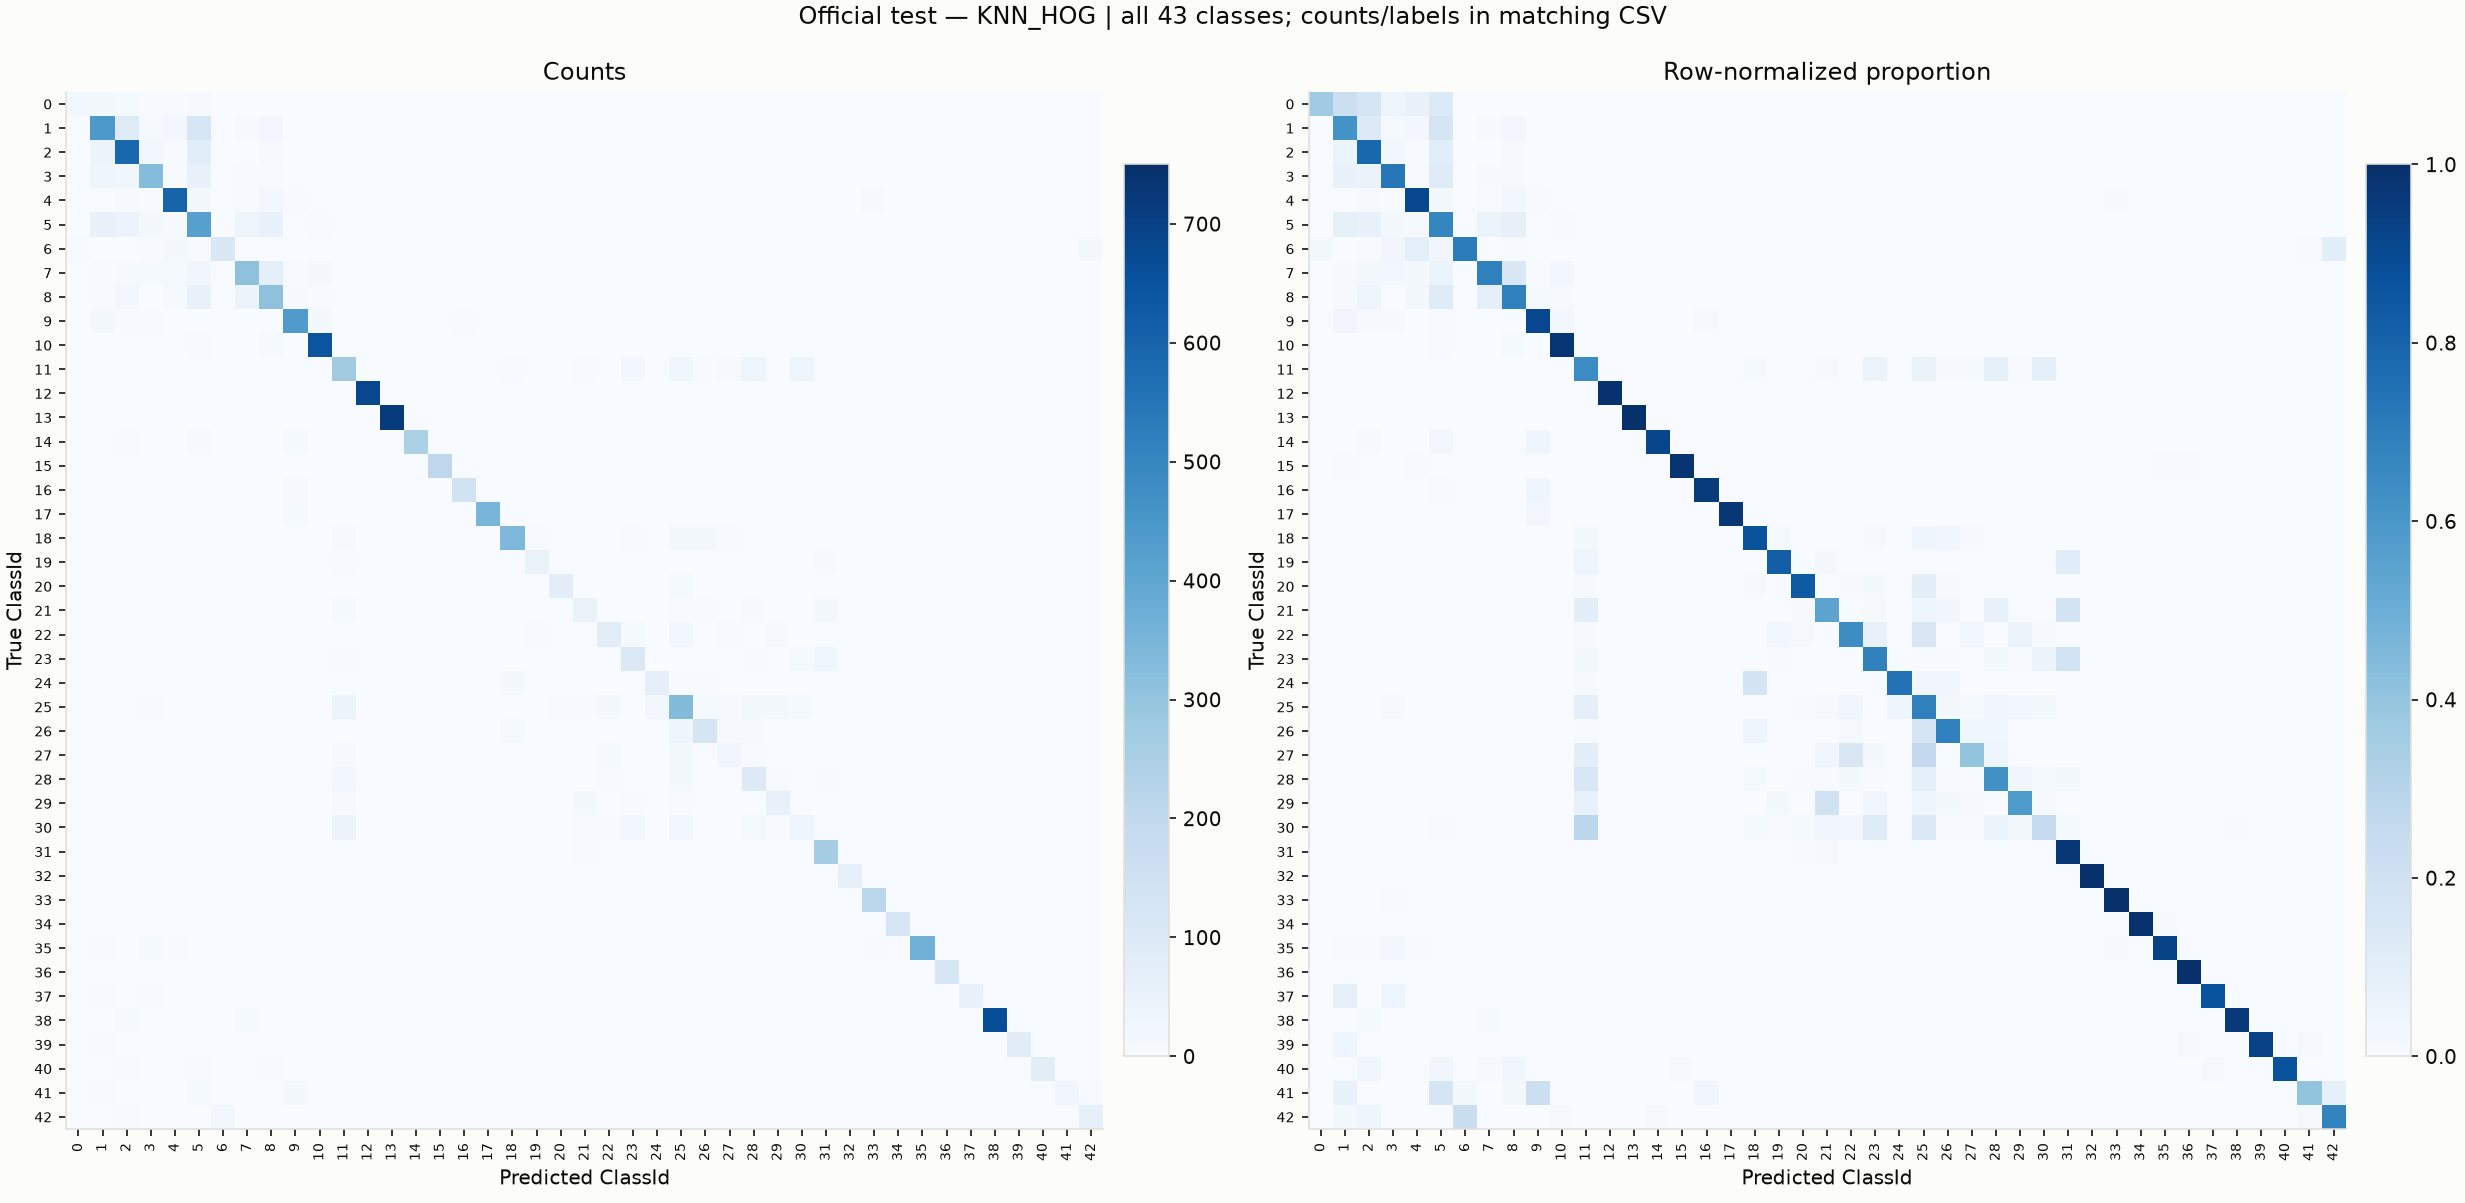

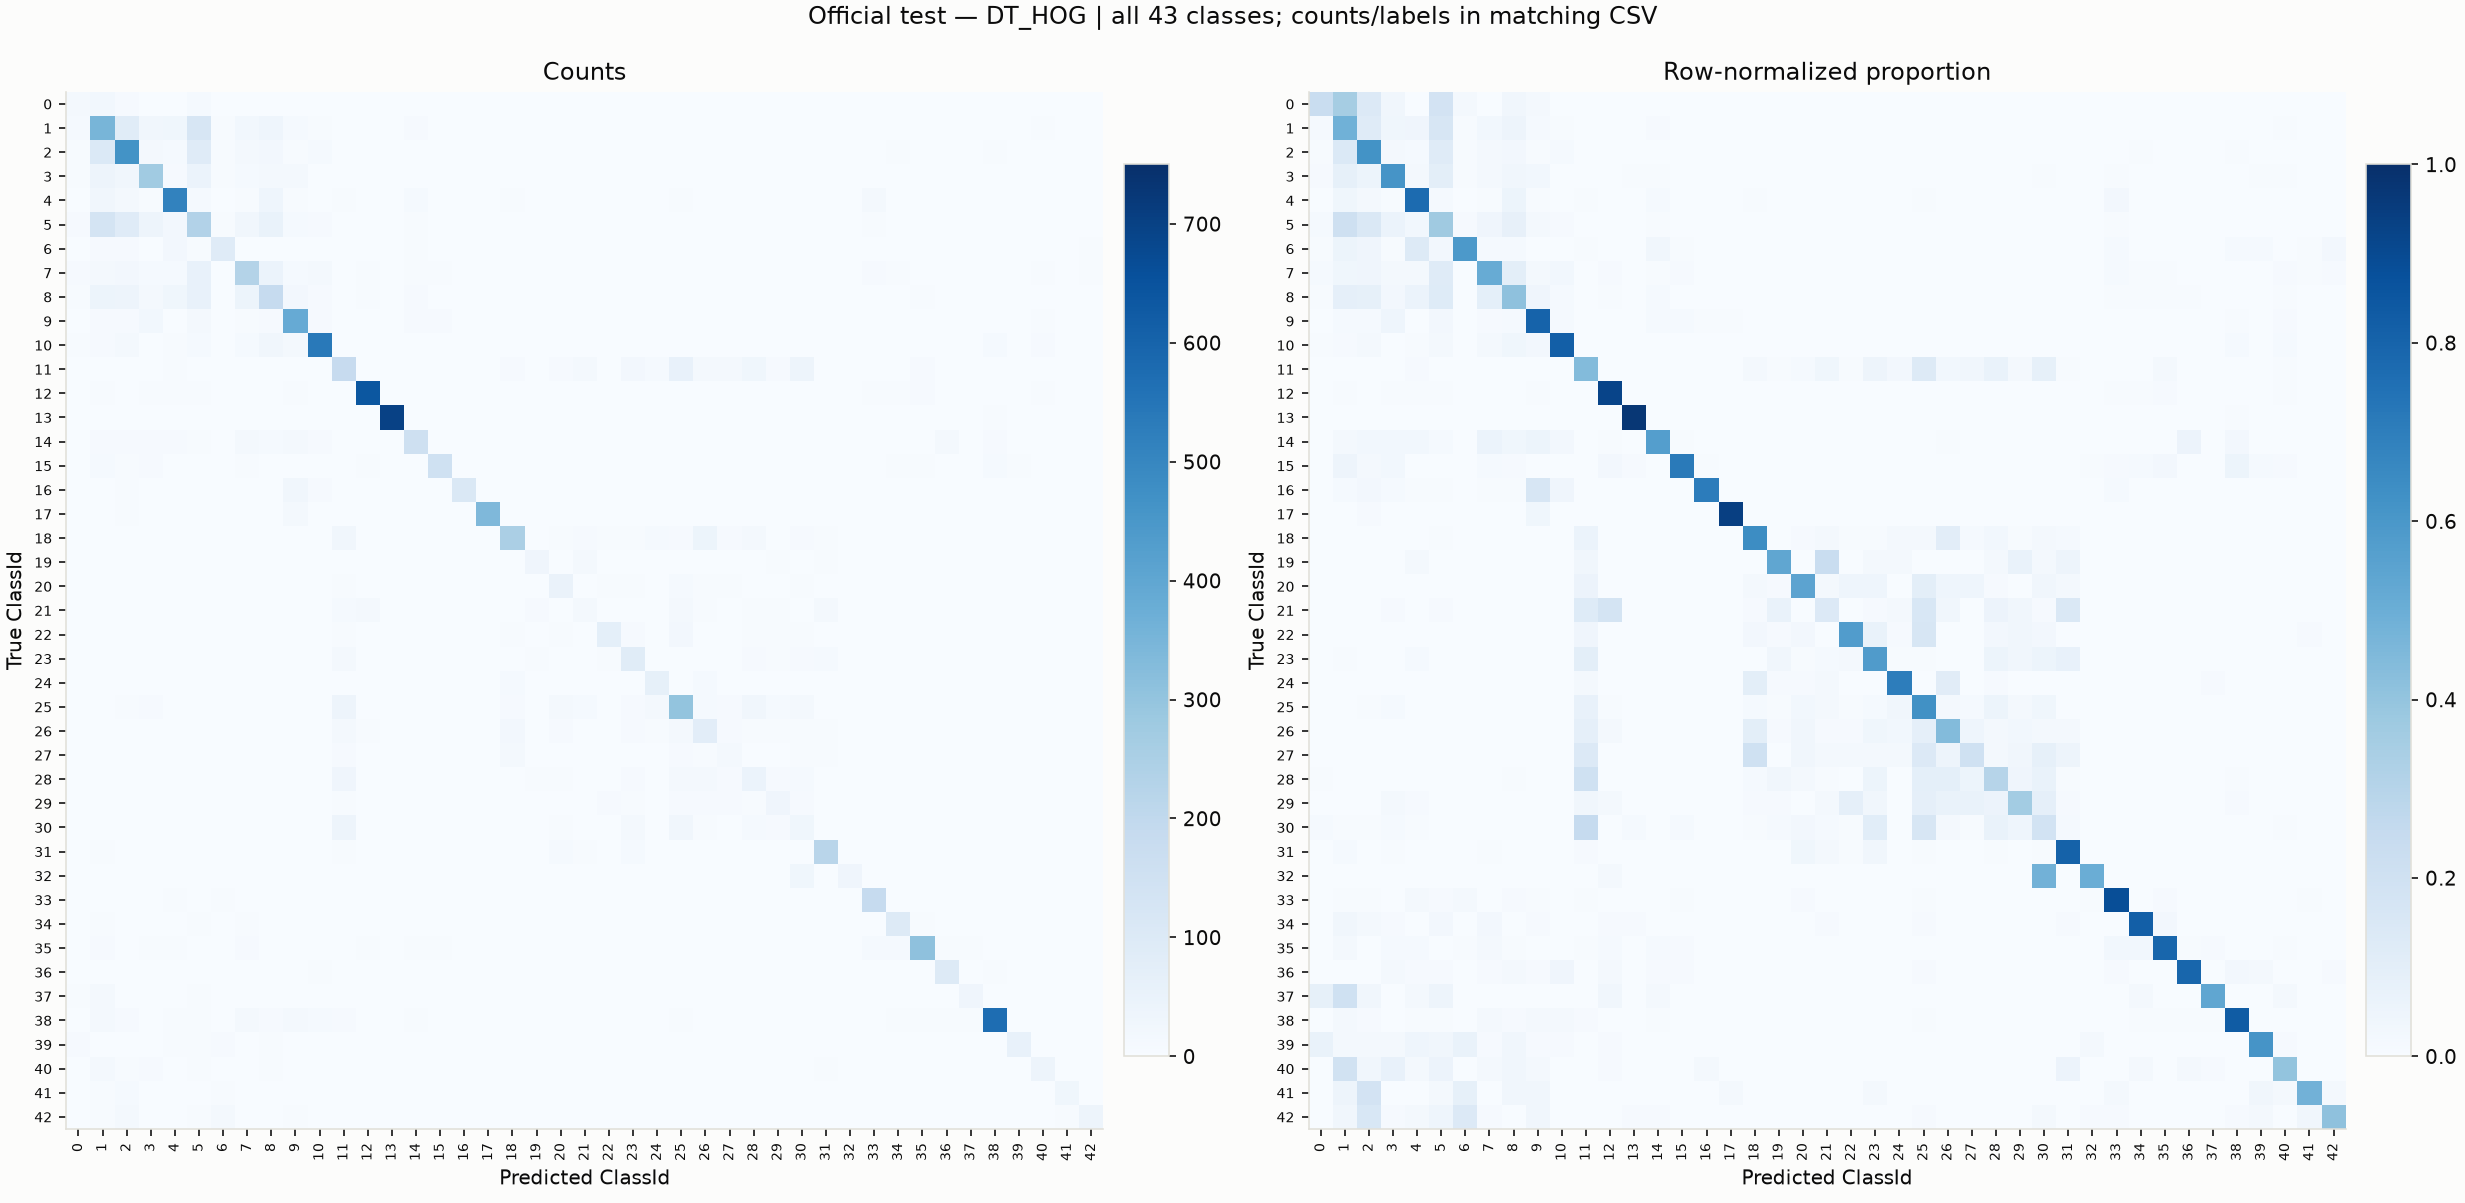

Các hình còn lại: knn_pixel, knn_hog_pca, dt_pixel, dt_hog_pca; xem report/figures.


In [3]:
mapping=pd.read_csv(TABLES/f'{PREFIX}_class_mapping.csv')
display(mapping)
for model in ['knn_hog','dt_hog']:
    display(Image(filename=str(FIGURES/f'{PREFIX}_cm_{model}.png')))
print('Các hình còn lại: knn_pixel, knn_hog_pca, dt_pixel, dt_hog_pca; xem report/figures.')
confusions=pd.read_csv(TABLES/f'{PREFIX}_official_confusions.csv')
assert len(confusions)==6*43*43
assert confusions.groupby(['algorithm','method'])['count'].sum().eq(12630).all()

## 4. H2 — lớp ít mẫu và hiệu năng từng lớp

Xem support cùng Precision/Recall/F1, không mặc định mọi lớp hiếm đều kém. Các track tạo nhiều frame gần nhau; số frame không phải số quan sát độc lập. H2 của EDA được đối chiếu mô tả ở đây, không chứng minh quan hệ nhân quả.

KNN weakest classes


,class_id,support,precision,recall,f1,correct,predicted_support,algorithm,method,split,class_name,train_images
73,30,150,0.366337,0.246667,0.294821,37,101,knn,hog,historical_official_test,Beware of ice/snow,450
70,27,60,0.444444,0.400000,0.421053,24,54,knn,hog,historical_official_test,Pedestrians,240
43,0,60,0.880000,0.366667,0.517647,22,25,knn,hog,historical_official_test,Speed limit 20,210
84,41,60,0.888889,0.400000,0.551724,24,27,knn,hog,historical_official_test,End of no passing,240
64,21,90,0.563218,0.544444,0.553672,49,87,knn,hog,historical_official_test,Double curve,330
71,28,150,0.540230,0.626667,0.580247,94,174,knn,hog,historical_official_test,Children crossing,540
48,5,630,0.519753,0.668254,0.584722,421,810,knn,hog,historical_official_test,Speed limit 80,1860
72,29,90,0.630952,0.588889,0.609195,53,84,knn,hog,historical_official_test,Bicycles crossing,270
54,11,420,0.644550,0.647619,0.646081,272,422,knn,hog,historical_official_test,Right-of-way at next intersection,1320
66,23,150,0.620482,0.686667,0.651899,103,166,knn,hog,historical_official_test,Slippery road,510


,class_id,support,precision,recall,f1,correct,predicted_support,algorithm,method,split,class_name,train_images
43,0,60,0.880000,0.366667,0.517647,22,25,knn,hog,historical_official_test,Speed limit 20,210
44,1,720,0.705230,0.618056,0.658771,445,631,knn,hog,historical_official_test,Speed limit 30,2220
62,19,60,0.790323,0.816667,0.803279,49,62,knn,hog,historical_official_test,Dangerous curve left,210
80,37,60,0.981132,0.866667,0.920354,52,53,knn,hog,historical_official_test,Go straight or left,210


DT weakest classes


,class_id,support,precision,recall,f1,correct,predicted_support,algorithm,method,split,class_name,train_images
193,21,90,0.148148,0.133333,0.140351,12,81,dt,hog,historical_official_test,Double curve,330
202,30,150,0.160920,0.186667,0.172840,28,174,dt,hog,historical_official_test,Beware of ice/snow,450
199,27,60,0.179104,0.200000,0.188976,12,67,dt,hog,historical_official_test,Pedestrians,240
172,0,60,0.181818,0.233333,0.204380,14,77,dt,hog,historical_official_test,Speed limit 20,210
200,28,150,0.292208,0.300000,0.296053,45,154,dt,hog,historical_official_test,Children crossing,540
201,29,90,0.351648,0.355556,0.353591,32,91,dt,hog,historical_official_test,Bicycles crossing,270
177,5,630,0.341679,0.368254,0.354469,232,679,dt,hog,historical_official_test,Speed limit 80,1860
180,8,450,0.403050,0.411111,0.407041,185,459,dt,hog,historical_official_test,Speed limit 120,1410
212,40,90,0.428571,0.400000,0.413793,36,84,dt,hog,historical_official_test,Roundabout mandatory,360
198,26,180,0.417989,0.438889,0.428184,79,189,dt,hog,historical_official_test,Traffic signals,600


,class_id,support,precision,recall,f1,correct,predicted_support,algorithm,method,split,class_name,train_images
172,0,60,0.181818,0.233333,0.204380,14,77,dt,hog,historical_official_test,Speed limit 20,210
173,1,720,0.415971,0.484722,0.447723,349,839,dt,hog,historical_official_test,Speed limit 30,2220
191,19,60,0.500000,0.533333,0.516129,32,64,dt,hog,historical_official_test,Dangerous curve left,210
209,37,60,0.680851,0.533333,0.598131,32,47,dt,hog,historical_official_test,Go straight or left,210


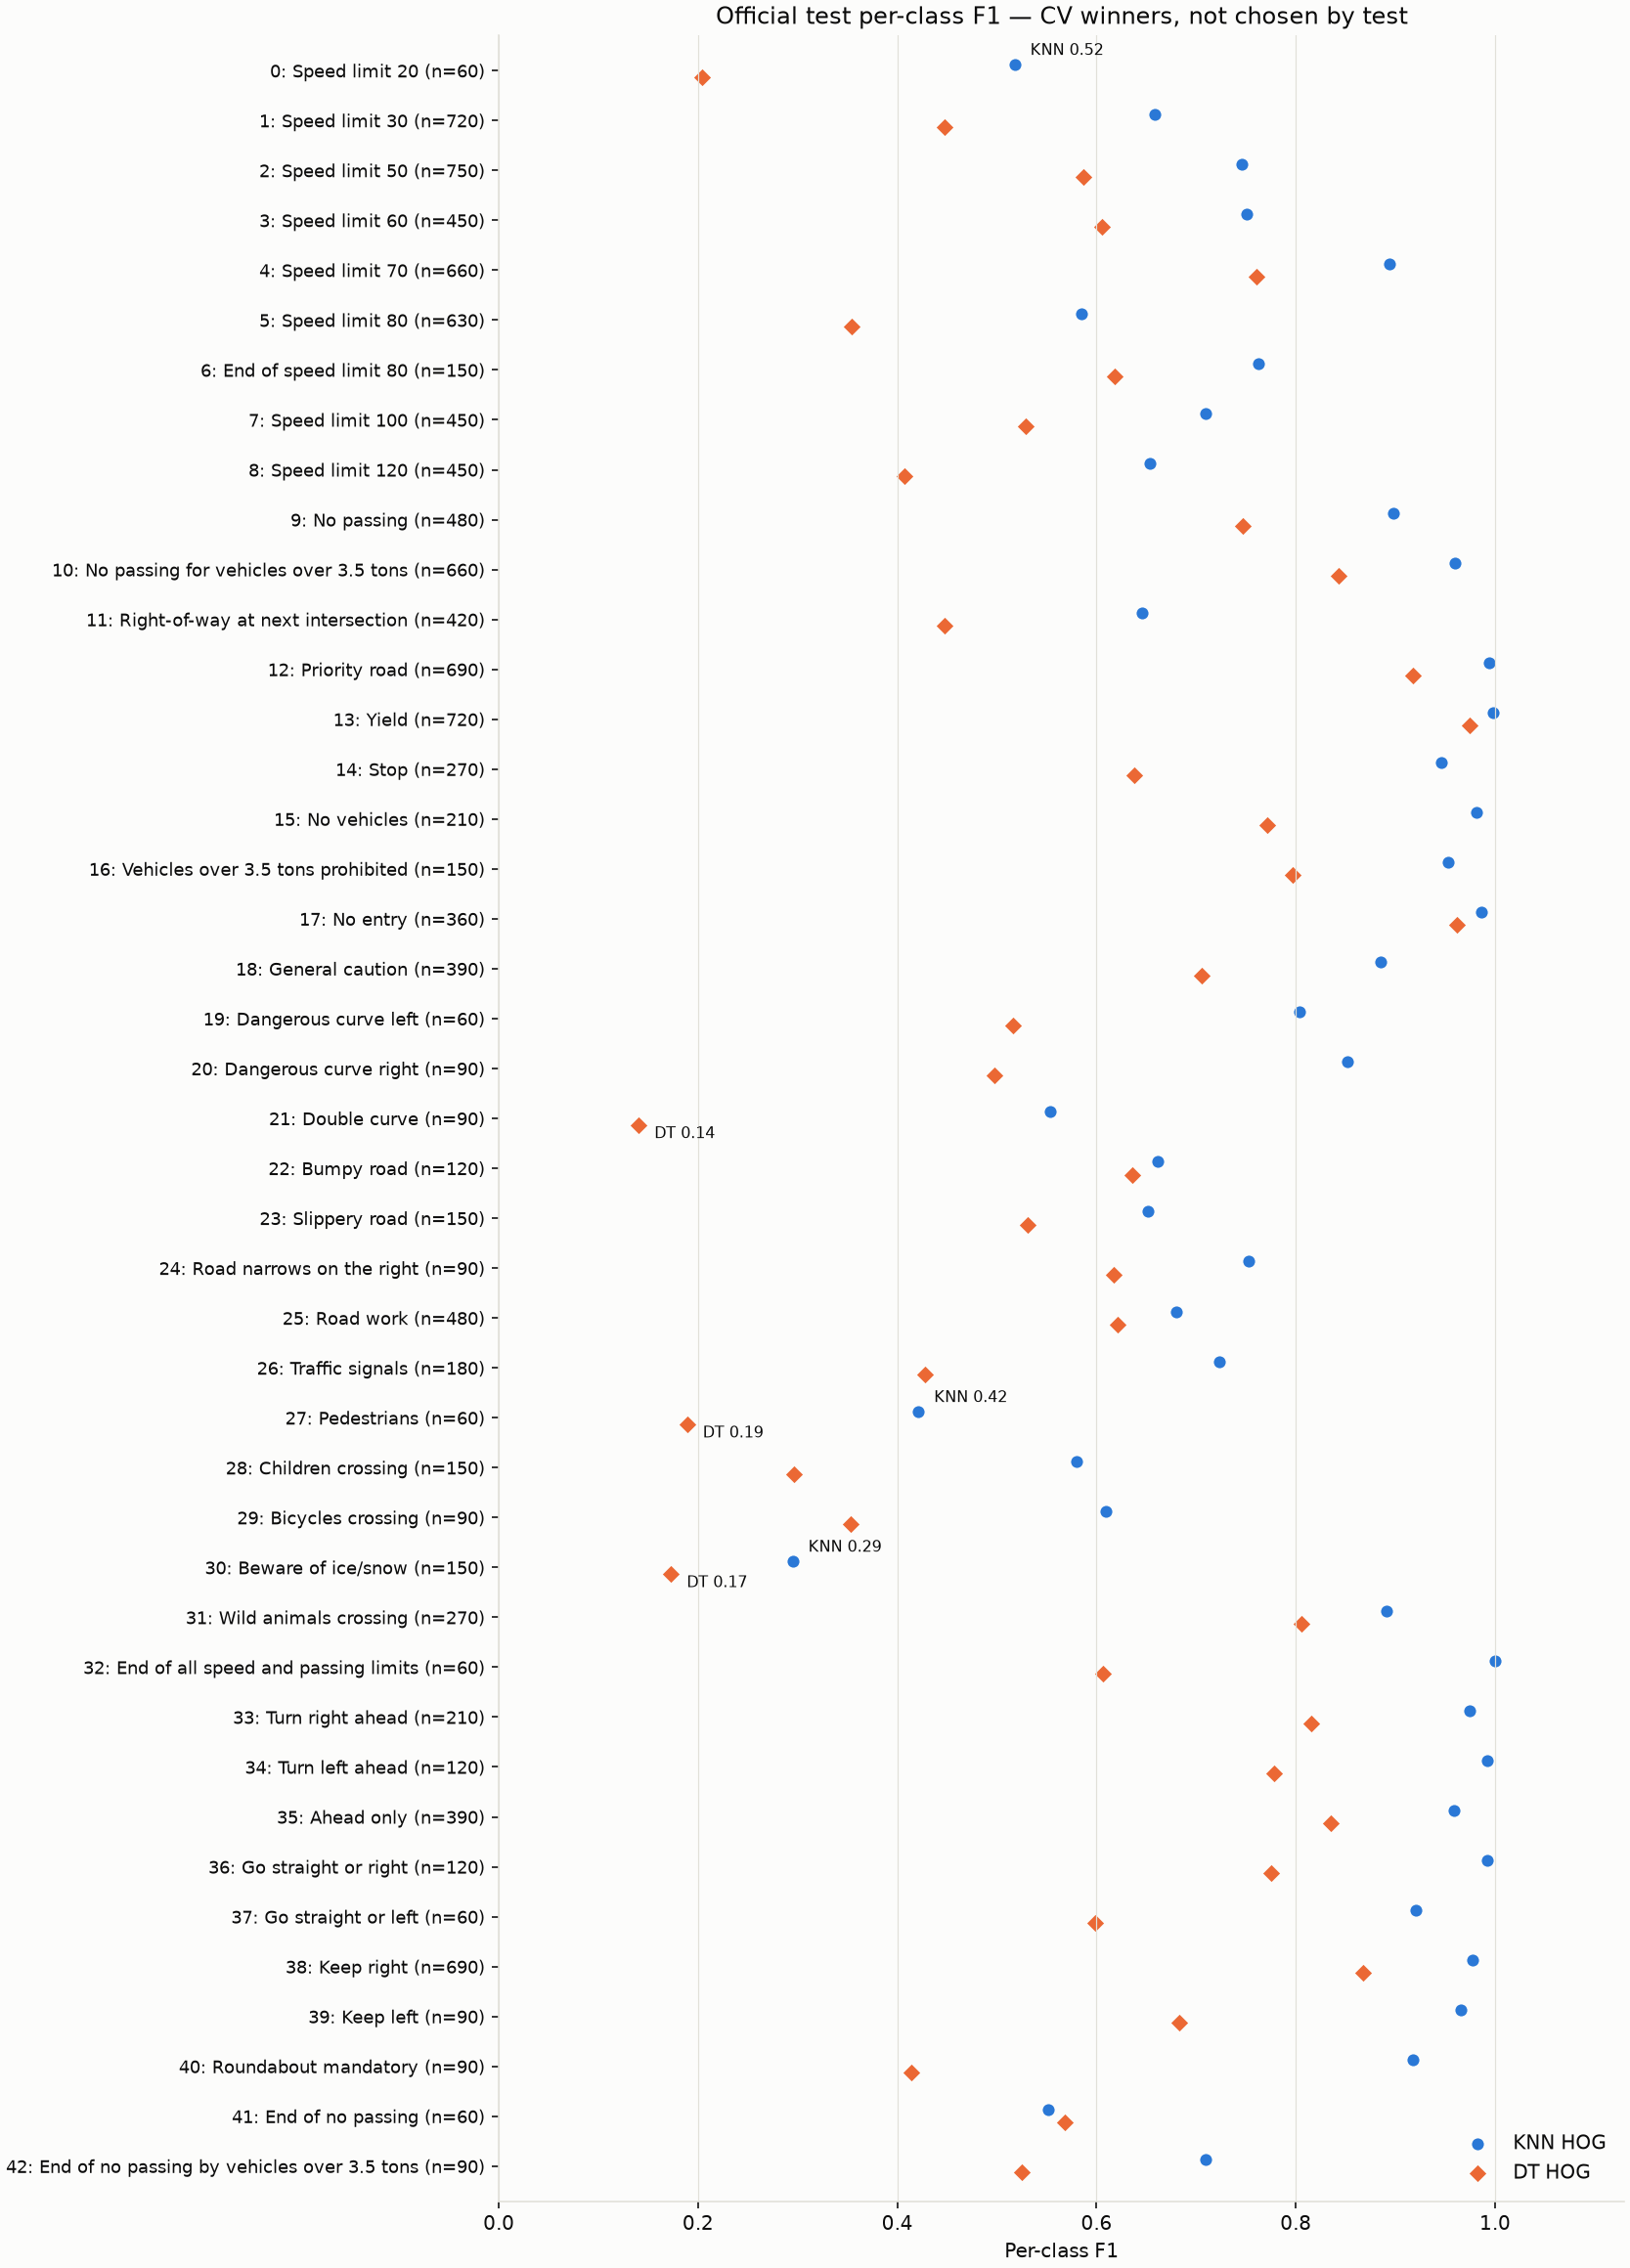

In [4]:
classes=pd.read_csv(TABLES/f'{PREFIX}_official_per_class.csv')
for algorithm in ['knn','dt']:
    part=classes.loc[classes.algorithm.eq(algorithm)&classes.method.eq('hog')]
    print(algorithm.upper(),'weakest classes')
    display(part.sort_values('f1').head(10))
    display(part.loc[part.class_id.isin([0,19,37,1])])
display(Image(filename=str(FIGURES/f'{PREFIX}_per_class_hog.png')))

## 5. H3 — kích thước và nhóm biển tốc độ

Ngưỡng min(W,H)<32 lấy từ EDA, không tìm ngưỡng tối đa hóa chênh lệch lỗi. Bảng phân nhóm không điều chỉnh class/track và không chứng minh ảnh nhỏ gây lỗi. Nhóm tốc độ gồm ClassId0,1,2,3,4,5,7,8. Không đổi cấu hình từ phân tích test này.

,dimension,group,n,errors,error_rate,algorithm,method,split
24,raw_min_dimension,ge32,10338,1684,0.162894,knn,hog,historical_official_test
25,raw_min_dimension,lt32,2292,610,0.266143,knn,hog,historical_official_test
26,roi_min_dimension,ge32,6552,932,0.142247,knn,hog,historical_official_test
27,roi_min_dimension,lt32,6078,1362,0.224087,knn,hog,historical_official_test
28,sign_family,other,8460,1143,0.135106,knn,hog,historical_official_test
29,sign_family,speed_limit,4170,1151,0.276019,knn,hog,historical_official_test
69,raw_min_dimension,ge32,10338,3281,0.317373,dt,hog,historical_official_test
70,raw_min_dimension,lt32,2292,1054,0.459860,dt,hog,historical_official_test
71,roi_min_dimension,ge32,6552,1897,0.289530,dt,hog,historical_official_test
72,roi_min_dimension,lt32,6078,2438,0.401119,dt,hog,historical_official_test


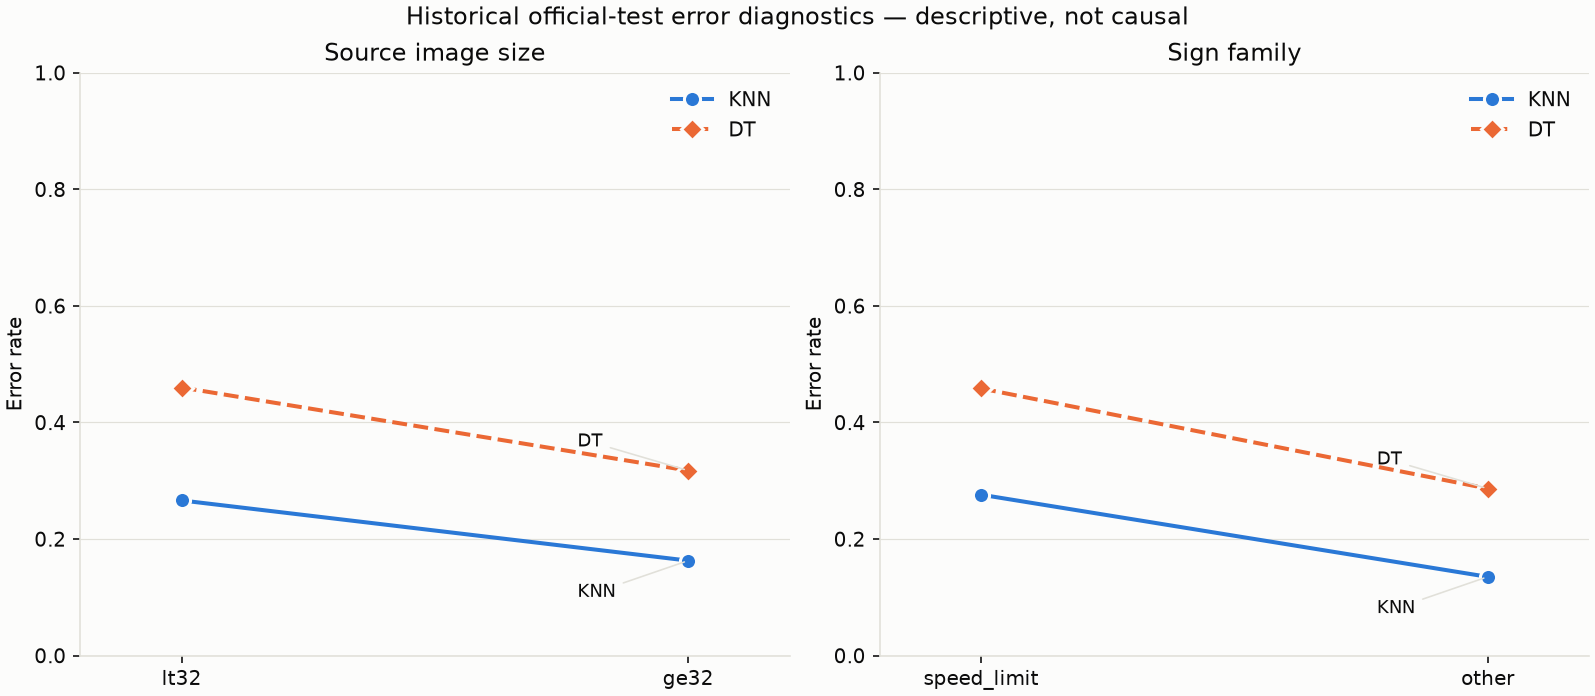

KNN

 top confusion pairs


,true_class,predicted_class,count,true_support,error_share_within_true,algorithm,method,split
547,1,5,119,720,0.165278,knn,hog,historical_official_test
548,1,2,93,720,0.129167,knn,hog,historical_official_test
549,2,5,81,750,0.108000,knn,hog,historical_official_test
550,7,8,65,450,0.144444,knn,hog,historical_official_test
551,5,1,54,630,0.085714,knn,hog,historical_official_test
552,3,5,53,450,0.117778,knn,hog,historical_official_test
553,8,5,53,450,0.117778,knn,hog,historical_official_test
554,5,8,51,630,0.080952,knn,hog,historical_official_test
555,2,1,45,750,0.060000,knn,hog,historical_official_test
556,25,11,44,480,0.091667,knn,hog,historical_official_test


DT top confusion pairs


,true_class,predicted_class,count,true_support,error_share_within_true,algorithm,method,split
1909,5,1,131,630,0.207937,dt,hog,historical_official_test
1910,1,5,118,720,0.163889,dt,hog,historical_official_test
1911,2,1,103,750,0.137333,dt,hog,historical_official_test
1912,2,5,89,750,0.118667,dt,hog,historical_official_test
1913,5,2,89,630,0.141270,dt,hog,historical_official_test
1914,1,2,86,720,0.119444,dt,hog,historical_official_test
1915,8,5,56,450,0.124444,dt,hog,historical_official_test
1916,7,5,53,450,0.117778,dt,hog,historical_official_test
1917,11,25,53,420,0.126190,dt,hog,historical_official_test
1918,5,8,51,630,0.080952,dt,hog,historical_official_test


In [5]:
groups=pd.read_csv(TABLES/f'{PREFIX}_official_error_groups.csv')
display(groups.loc[groups.method.eq('hog')&groups.dimension.isin(['raw_min_dimension','roi_min_dimension','sign_family'])])
display(Image(filename=str(FIGURES/f'{PREFIX}_official_error_groups.png')))
pairs=pd.read_csv(TABLES/f'{PREFIX}_official_error_pairs.csv')
for algorithm in ['knn','dt']:
    print(algorithm.upper(),'top confusion pairs')
    display(pairs.loc[pairs.algorithm.eq(algorithm)&pairs.method.eq('hog')].head(12))

## 6. Ví dụ ảnh dự đoán sai

Chọn4 cặp nhầm thường gặp,2 ảnh mỗi cặp theo thứ tự SHA256(seed42|Path). Đây là mẫu minh họa xác định, không phải mẫu ngẫu nhiên đại diện. Hiển thị ảnh gốc và ROI đúng CSV để người học kiểm tra; caption chỉ ghi true/prediction, không gán nguyên nhân chủ quan. Các hình không thay cho kiểm định định lượng.

,CSVRow,Path,ClassId,PredictedClassId,pair_rank,example_rank,algorithm,method
0,9995,Test/09995.png,1,5,1,1,knn,hog
1,517,Test/00517.png,1,5,1,2,knn,hog
2,7546,Test/07546.png,1,2,2,1,knn,hog
3,10358,Test/10358.png,1,2,2,2,knn,hog
4,2144,Test/02144.png,2,5,3,1,knn,hog
5,8459,Test/08459.png,2,5,3,2,knn,hog
6,9761,Test/09761.png,7,8,4,1,knn,hog
7,150,Test/00150.png,7,8,4,2,knn,hog
8,12484,Test/12484.png,5,1,1,1,dt,hog
9,11370,Test/11370.png,5,1,1,2,dt,hog


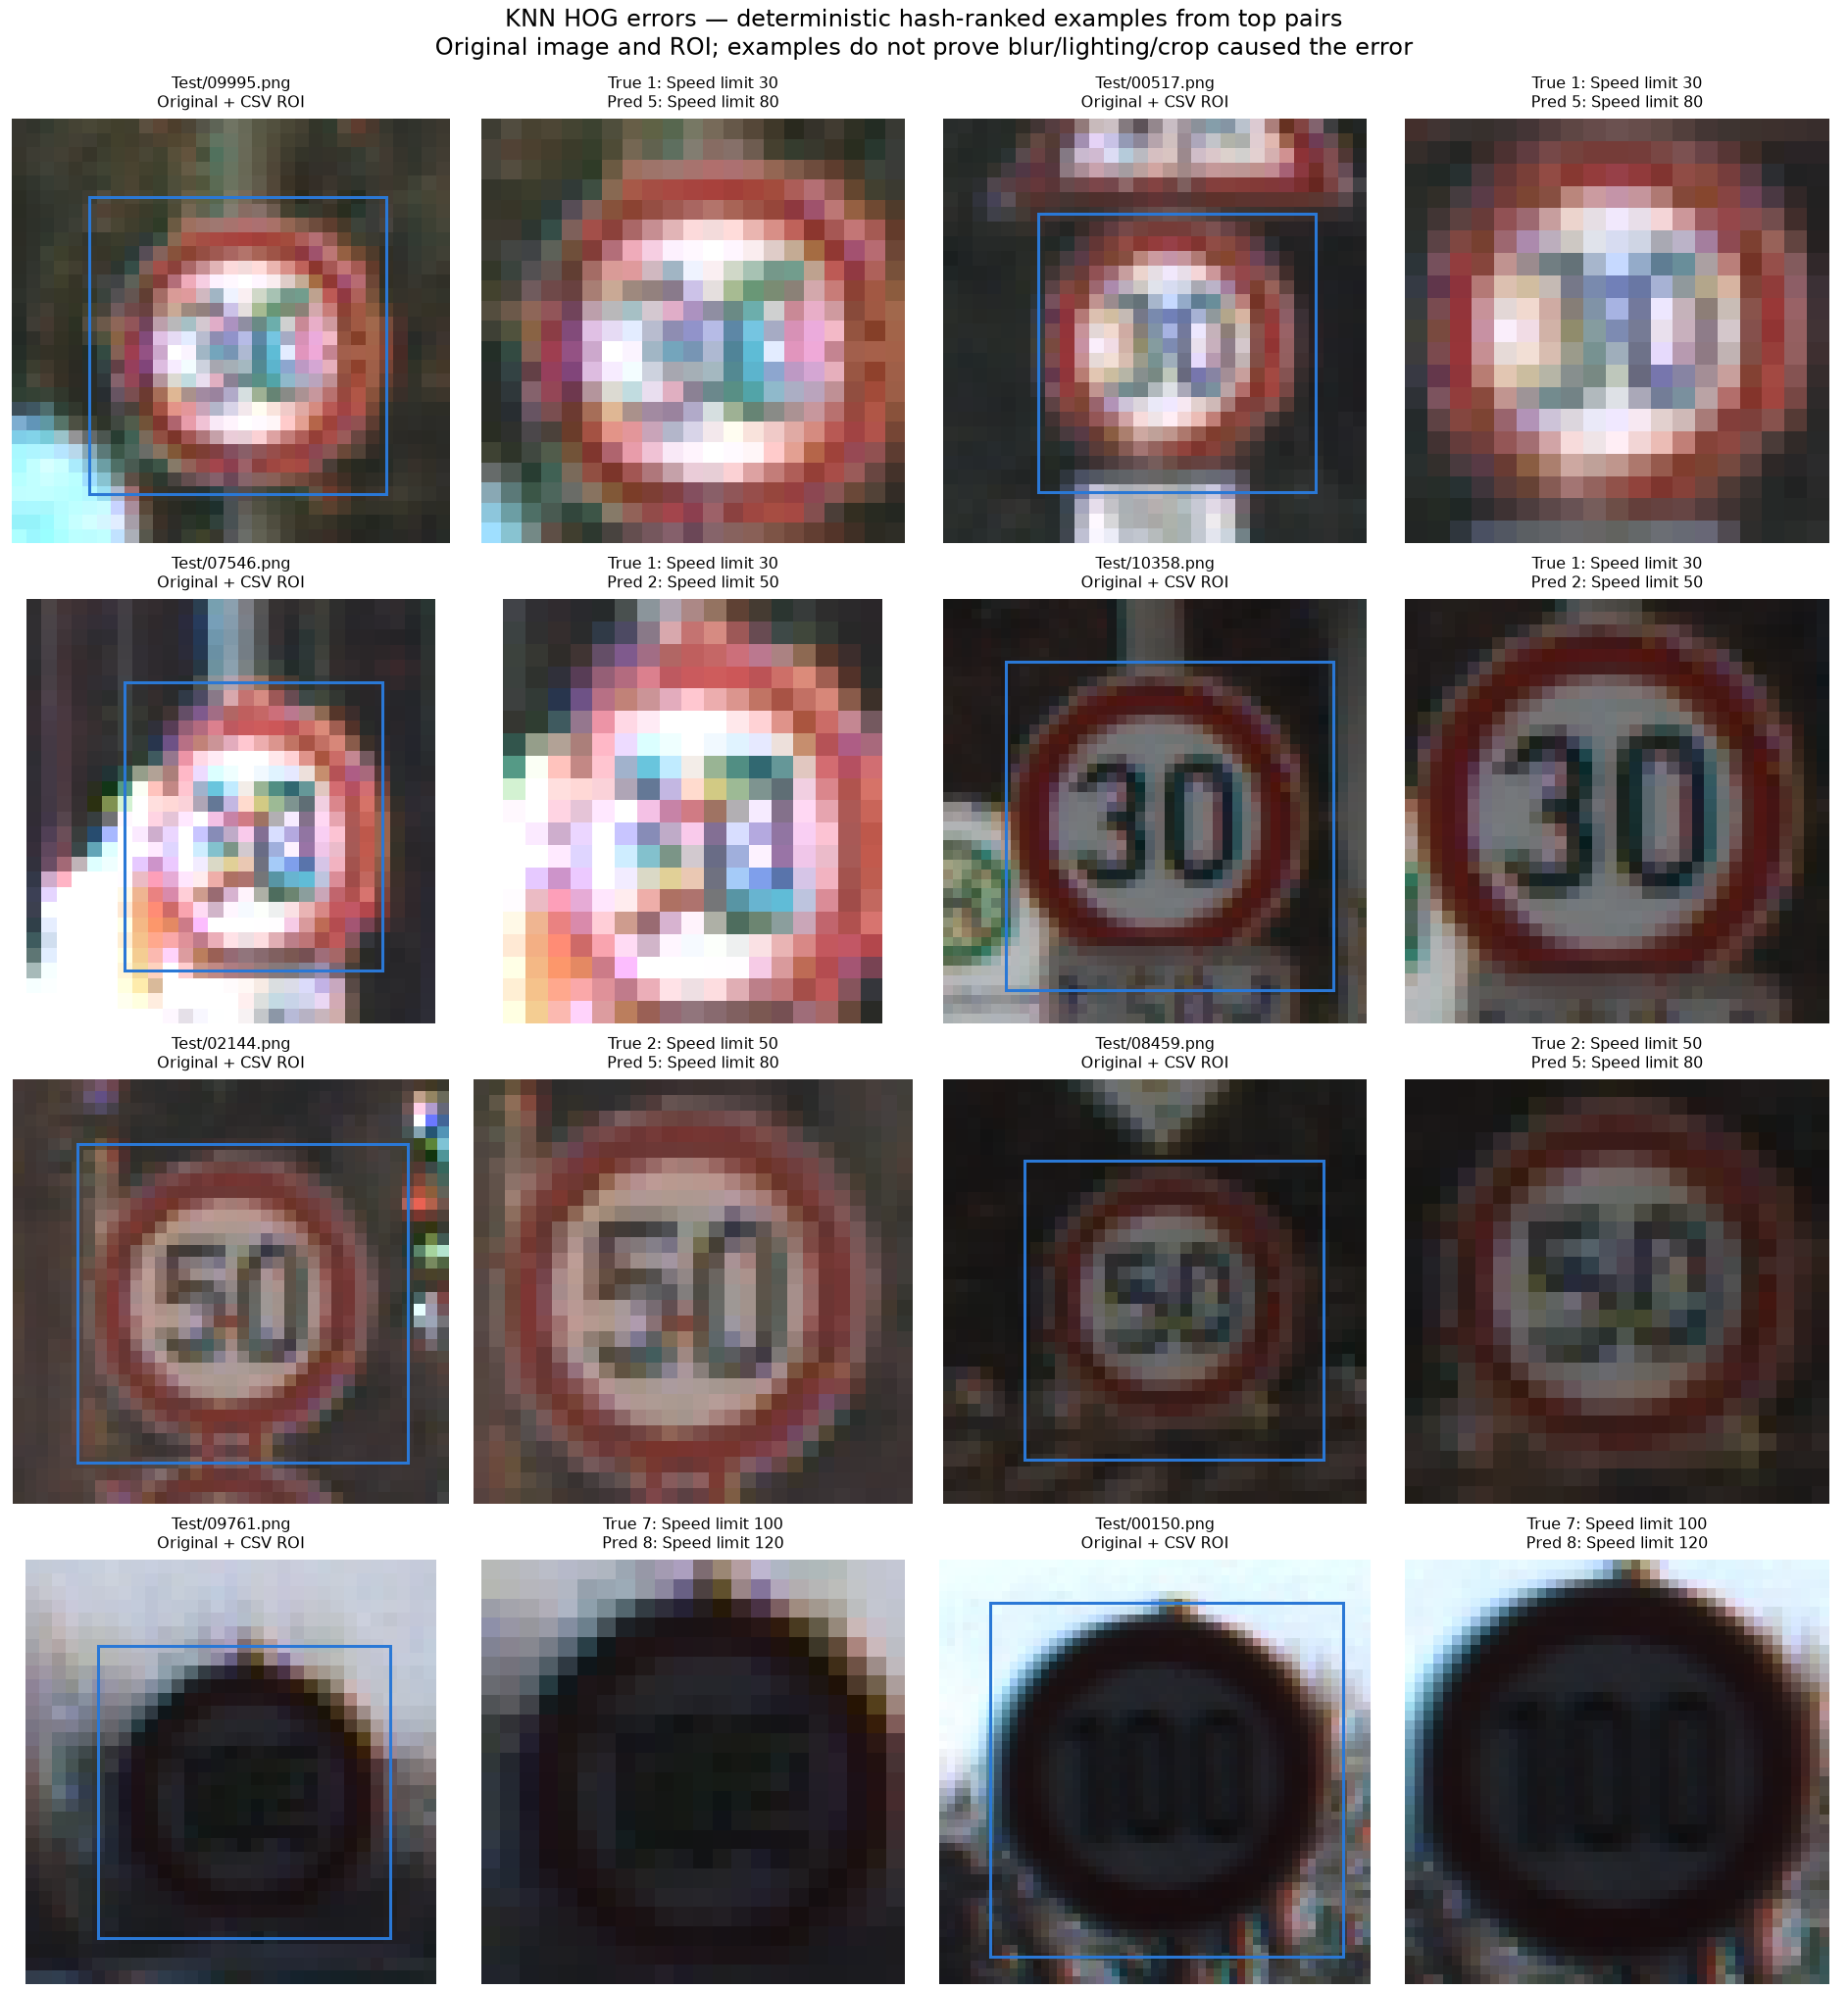

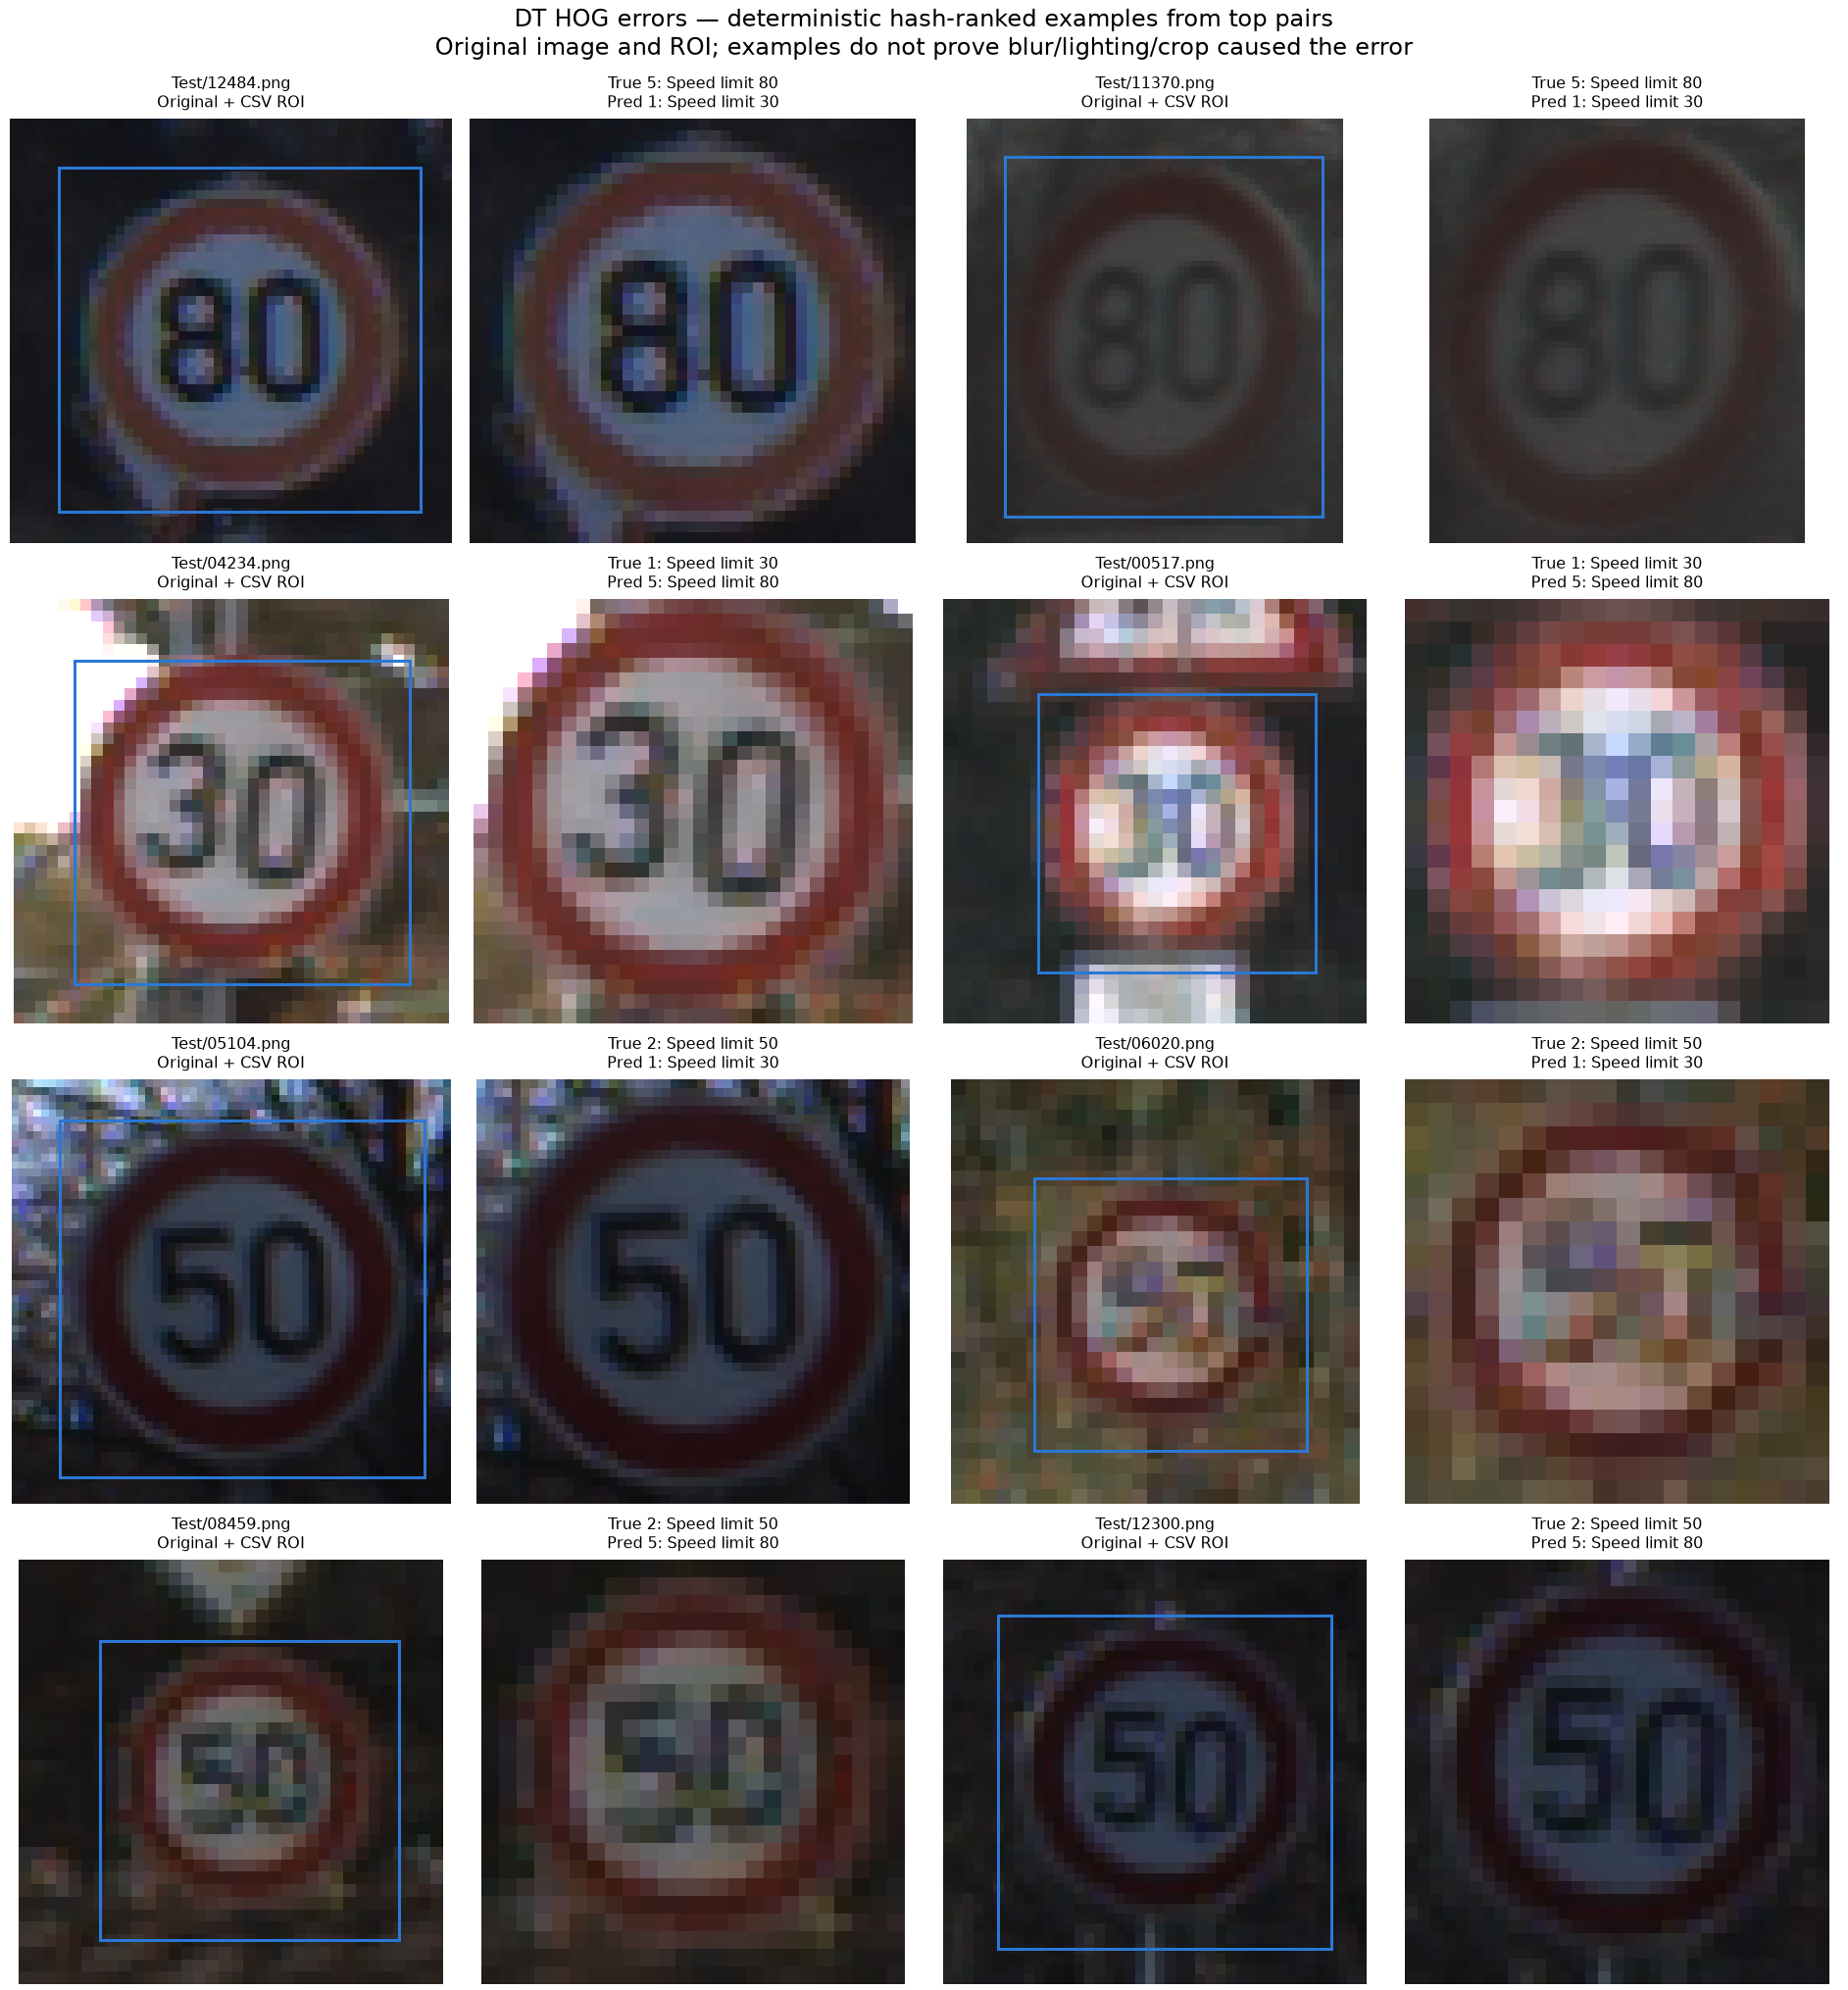

In [6]:
examples=pd.read_csv(TABLES/f'{PREFIX}_error_examples.csv')
display(examples)
for algorithm in ['knn','dt']:
    display(Image(filename=str(FIGURES/f'{PREFIX}_error_gallery_{algorithm}_hog.png')))

## 7. So sánh ghép cặp KNN–DT

Các mô hình được đối chiếu trên cùng ảnh: cả hai đúng, chỉ KNN đúng, chỉ DT đúng, cả hai sai. Đây là đếm mô tả, không p-value/CI; không giả định các frame độc lập. Không coi chênh lệch trên một benchmark là ưu thế phổ quát.

In [7]:
paired=pd.read_csv(TABLES/f'{PREFIX}_official_paired.csv')
display(paired)

,split,method,name_first,name_second,n,both_correct,first_only_correct,second_only_correct,both_wrong,accuracy_difference_first_minus_second,discordant
0,historical_official_test,pixel,knn,dt,12630,5392,1646,2632,2960,-0.078068,4278
1,historical_official_test,hog,knn,dt,12630,7696,2640,599,1695,0.161599,3239
2,historical_official_test,hog_pca,knn,dt,12630,6969,3093,503,2065,0.205067,3596


## 8. Audit trùng byte giữa official train/test

SHA256 bytes ảnh kiểm tra trùng chính xác, không phát hiện mọi near-duplicate. Giữ nguyên official split; không loại ảnh khỏi metrics để tạo một benchmark khác. Số cặp trùng không tự định lượng ảnh hưởng đến hiệu năng.

In [8]:
overlap=pd.read_csv(TABLES/f'{PREFIX}_exact_split_overlap.csv')
display(overlap)
assert len(overlap)==provenance['exact_duplicate_pairs']
print('Exact byte pairs:',len(overlap),'— split unchanged')

,train_path,train_class,test_path,test_class,test_csv_row,image_sha256,equal_label
0,Train/14/00014_00023_00019.png,14,Test/00666.png,14,666,22c2ebb268a96cd989b933fb3270b82ada18c3c9d1f83b...,True
1,Train/14/00014_00023_00000.png,14,Test/02291.png,14,2291,8a22106f2c2a896f7ae263290e6558d4a669569b9fa75c...,True
2,Train/14/00014_00023_00013.png,14,Test/03546.png,14,3546,b91e2616cf4a5d164cf2897f8aae35ea0254d3d42bd282...,True
3,Train/14/00014_00023_00010.png,14,Test/03594.png,14,3594,0d6579102c3c1428117cc6e1e6cc9b7bd35af517c09736...,True
4,Train/14/00014_00023_00006.png,14,Test/04548.png,14,4548,49f9139869352da0dc0ada91fc1c38eb2d47c96e1cca33...,True
5,Train/14/00014_00023_00007.png,14,Test/09384.png,14,9384,b2d7d0042534146cc0bf99d58d8fa30e249d261c0b63f7...,True
6,Train/14/00014_00023_00016.png,14,Test/09575.png,14,9575,e52b9d0ee291b0ceac761d932fc848481def8f42ac84da...,True
7,Train/14/00014_00023_00003.png,14,Test/11906.png,14,11906,ab3283724c2225a31f394979a2988e725a726b37f8ea4f...,True


Exact byte pairs: 8 — split unchanged


## 9. Kết quả nâng cấp: chỉ OOF train, không trộn với official test

Model mới do Đặng Quang Tiến nâng cấp phần KNN/DT của Nguyễn Hoàng. Bảng OOF có selection bias vì cấu hình được chọn trên chính folds đó; không phải nested/unbiased evaluation. Không so OOF F1 trực tiếp với official-test F1 như một mức cải thiện. Xem notebook03 để biết grid, delta từng fold và train–validation gap.

In [9]:
oof=pd.read_csv(TABLES/f'{PREFIX}_upgrade_oof_summary.csv')
oof_pairs=pd.read_csv(TABLES/f'{PREFIX}_upgrade_oof_paired.csv')
display(oof)
display(oof_pairs)
print('No new official-test score for upgraded models.')

,split,algorithm,role,n,accuracy,precision_macro,recall_macro,f1_macro,balanced_accuracy,mean_fold_f1_macro,std_fold_f1_macro,params
0,train_oof_same_fold_selection,knn,baseline,39209,0.822311,0.841081,0.792981,0.812176,0.792981,0.809718,0.016981,"{""metric"": ""manhattan"", ""n_neighbors"": 7, ""wei..."
1,train_oof_same_fold_selection,knn,selected,39209,0.827030,0.847974,0.792231,0.813967,0.792231,0.812096,0.014242,"{""metric"": ""manhattan"", ""n_neighbors"": 15, ""we..."
2,train_oof_same_fold_selection,dt,baseline,39209,0.658777,0.633867,0.604277,0.616536,0.604277,0.614898,0.011907,"{""ccp_alpha"": 0.0, ""class_weight"": null, ""crit..."
3,train_oof_same_fold_selection,dt,selected,39209,0.666939,0.642631,0.610090,0.623811,0.610090,0.621998,0.013418,"{""ccp_alpha"": 0.0005, ""class_weight"": null, ""c..."


,split,algorithm,name_first,name_second,n,both_correct,first_only_correct,second_only_correct,both_wrong,accuracy_difference_first_minus_second,discordant
0,train_oof_same_fold_selection,knn,selected,baseline,39209,31438,989,804,5978,0.004718,1793
1,train_oof_same_fold_selection,dt,selected,baseline,39209,24793,1357,1037,12022,0.008161,2394


No new official-test score for upgraded models.


## 10. Giới hạn và tái lập

- Bài toán phân loại biển đã định vị, không detection hay kiểm chứng an toàn thực địa.
- Test đã được EDA xem; trùng byte không loại trừ near-duplicate.
- Một seed/ba fold; chưa nested/repeated CV hoặc CI theo track.
- Không gán blur/ánh sáng là nguyên nhân; preprocessing/features người1/2 không đổi.
- Phần mô hình gộp trong report/knn và report/dt; xem [notebook03](03_models.ipynb), [KNN](../report/notes_knn.md), [DT](../report/notes_dt.md).
- Run All chỉ đọc artifacts. Đánh giá mới phải dùng run-id mới, không inference lại:

```powershell
& data/.venv-model3/Scripts/python.exe scripts/evaluate_saved_models.py --dataset-dir data --knn-run report/knn/hog-full-20261115 --dt-run report/dt/hog-full-20261115 --run-id tien-evaluation-new
```

Logs trong logs/evaluation; báo cáo report/notes_evaluation_tien.md. Thành viên tự xác minh và chịu trách nhiệm.